# Revisão Sistemática da Literatura sobre Coordenação de Sistemas Multi-Robô no Contínuo Físico-Cibernético (RC-SCF)

# Etapa Atual: Análise Exploratória e Triagem de Elegibilidade

**Projeto:** RSL — Coordenação de Sistemas Multi-Robô no Contínuo Físico-Cibernético (RC-SCF)  
**Data de Execução da Busca:** 06/11/2026  
**Fase Atual:** Análise de Dados e Triagem por Título e Resumo (*Title & Abstract Screening*) sobre os **740 artigos únicos** obtidos via Zotero.

---

### 1. Funil de Seleção (Situação Atual)
* **Busca Bruta:** 11.563 registros obtidos nas bases Scopus, IEEE Xplore e Web of Science.
* **Amostragem por Citações:** Exportação dos ~200 artigos mais citados por combinação de string e base (~1.800 registros).
* **Deduplicação (Zotero):** Consolidação em **740 artigos únicos** (carregados no CSV deste notebook).
* **Meta da Etapa:** Triar até **100 candidatos** para leitura integral, visando o teto de **40 estudos incluídos** na síntese final.

---

### 2. Fontes de Dados e Parâmetros de Busca
| Base de Dados | Campo de Busca | Filtros Utilizados |
| :--- | :--- | :--- |
| **Scopus** | `TITLE-ABS-KEY(...)` | 2020–2026, Idioma Inglês, *Articles* & *Conference Papers* |
| **Web of Science** (Core Collection) | `TS=(...)` | 2020–2026, Idioma Inglês, *Article* & *Proceedings Paper* |
| **IEEE Xplore** | Title, Abstract, Keywords | 2020–2026, *Journals* & *Conferences* |

---

### 3. Composição das Strings de Busca
| String | Composição | Foco Principal | RQs Atendidas |
| :--- | :--- | :--- | :--- |
| **S1 — Continuum/CPS** | `N1 AND N3` | Infraestrutura continuum, Gêmeos Digitais, HIL | RQ2 (e RQ1) |
| **S2 — Redes/QoS** | `N1 AND N2` | Comunicação, protocolos, middlewares, QoS | RQ3 (e RQ1) |
| **S3 — Heterogeneidade** | `N1 AND H AND (N2 OR N3)` | Frotas heterogêneas com rede ou continuum | RQ1 a RQ3 |

* **N1 (Frota Robótica):** *multi-robot*, *swarms*, *fleets*, *UAV*, *AGV*, *multi-agent*.
* **H (Heterogeneidade):** *heterogeneous*, *air-ground*, *mixed fleet*.
* **N2 (Comunicação & Redes):** *wireless*, *latency*, *QoS*, *ROS 2*, *Zenoh*, *5G/6G*, *MANET/FANET*.
* **N3 (Integração Físico-Cibernética):** *edge/fog/cloud computing*, *digital twin*, *computing continuum*.

---

### 4. Critérios de Elegibilidade

#### Critérios de Inclusão (IC)
| Código | Critério | Descrição / Detalhamento |
| :--- | :--- | :--- |
| **IC1** | **Sistemas Multi-Robô** | Estuda sistemas com 2 ou mais agentes robóticos ($\ge 2$). |
| **IC2** | **Alinhamento com Taxonomia** | Aborda ao menos um ramo da taxonomia RC-SCF (*Scope*, *Decision*, *Processing*, *Model*, *Comm*). |
| **IC3** | **Contribuição Técnica Explícita** | Descrição clara de arquitetura, protocolo de comunicação, middleware ou modelo algorítmico. |
| **IC4** | **Tipo & Idioma** | Artigos completos em periódicos ou conferências com revisão por pares, no idioma inglês. |
| **IC5** | **Janela Temporal** | Publicado entre os anos de 2020 e 2026. |

#### Critérios de Exclusão (EC)
| Código | Critério | Descrição / Detalhamento |
| :--- | :--- | :--- |
| **EC1** | **Single-Robot** | Focado em apenas um robô ou agente individual (*single-agent*). |
| **EC2** | **Ausência de Rede/Continuum** | Estudos de MRS sem elementos de comunicação/rede ou de contínuo físico-cibernético. |
| **EC3** | **Texto Curto/Não Artigo** | Artigos curtos ($< 4$ páginas), editoriais, resumos de pôsteres e keynotes. |
| **EC4** | **Texto Inacessível** | Texto completo inacessível para download via Portal CAPES. |
| **EC5** | **Fora do Domínio** | Estudos fora da área de Engenharia e Robótica. |
| **EC6** | **Estudos Secundários** | Revisões da literatura ou surveys (salvos apenas para *snowballing*). |
| **EC7** | **Redundância** | Versões anteriores ou duplicadas do mesmo trabalho. |
| **EC8** | **Sem Revisão por Pares** | Preprints não revisados por pares (ex.: arXiv). |

---

### 5. Objetivos do Notebook
1. **Análise Descritiva:** Mapear a distribuição temporal (2020–2026), principais veículos de publicação, contagem de citações e taxa de artigos em *Open Access*.
2. **Triagem de Elegibilidade:** Aplicar os critérios IC1–IC5 e EC1–EC8 sobre os 740 artigos via título e resumo.

3. **Exportação de Candidatos:** Gerar o subconjunto de até **100 artigos pré-selecionados** para a leitura integral e extração final.

In [2]:
import pandas as pd
import numpy as np
import re
from google.colab import drive

# Montagem do Drive
drive.mount('/content/drive')

# Caminhos dos arquivos
caminho_original = '/content/drive/MyDrive/Colab Notebooks/PRE-TRIAGEM/Parte1.csv'
caminho_organizado = '/content/drive/MyDrive/Colab Notebooks/PRE-TRIAGEM/DataBase.csv'

df_raw = pd.read_csv(caminho_original)

# Mapeamento de colunas cruciais (incluindo Manual Tags)
mapeamento_colunas = {
    'Key': 'id_zotero',
    'Title': 'titulo',
    'Author': 'autores',
    'Publication Year': 'ano',
    'Publication Title': 'veiculo',
    'Item Type': 'tipo_item',
    'DOI': 'doi',
    'Place': 'pais_local',
    'Manual Tags': 'manual_tags',
    'Abstract Note': 'abstract'
}

cols_existentes = {k: v for k, v in mapeamento_colunas.items() if k in df_raw.columns}
df = df_raw[list(cols_existentes.keys())].rename(columns=cols_existentes).copy()

# 1. Extração de Citações (Prioridade: Notes -> Extra -> Colunas Diretas)
def extrair_citacoes(row):
    notes = str(row.get('Notes', ''))
    match_notes = re.search(r'Cited\s+By:\s*(\d+)', notes, re.IGNORECASE)
    if match_notes:
        return int(match_notes.group(1))

    extra = str(row.get('Extra', ''))
    match_extra = re.search(r'(?:Citations|Cited\s+by|TC):\s*(\d+)', extra, re.IGNORECASE)
    if match_extra:
        return int(match_extra.group(1))

    for col in ['Citations', 'Citation Count', 'Times Cited', 'TC']:
        if col in row and pd.notna(row[col]):
            try:
                return int(row[col])
            except ValueError:
                pass
    return 0

df['citacoes'] = df_raw.apply(extrair_citacoes, axis=1)

# 2. Cálculo do Número de Páginas a partir da coluna Pages
def calcular_num_paginas(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    match = re.search(r'(\d+)\s*[\–\-]\s*(\d+)', val_str)
    if match:
        p_inicio, p_fim = int(match.group(1)), int(match.group(2))
        if p_fim >= p_inicio:
            return p_fim - p_inicio + 1
    return np.nan

if 'Pages' in df_raw.columns:
    df['num_paginas'] = df_raw['Pages'].apply(calcular_num_paginas)
else:
    df['num_paginas'] = np.nan

# Tratamento do ano
if 'ano' in df.columns:
    df['ano'] = pd.to_numeric(df['ano'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')

# Mapeamento do tipo de veículo
if 'tipo_item' in df.columns:
    tipo_map = {
        'journalArticle': 'Revista (Journal)',
        'conferencePaper': 'Artigo de Congresso (Conference)',
        'bookSection': 'Capítulo de Livro',
        'report': 'Relatório Técnico'
    }
    df['tipo_veiculo_rotulo'] = df['tipo_item'].map(tipo_map).fillna(df['tipo_item'])

# Coluna de controle para triagem
df['decisao'] = 'Pendente'

# Limpeza de strings
cols_texto = ['titulo', 'abstract', 'veiculo', 'autores', 'pais_local', 'doi', 'manual_tags']
for col in cols_texto:
    if col in df.columns:
        df[col] = df[col].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

# Seleção e ordenação final das colunas
ordem_colunas = [
    'id_zotero', 'titulo', 'autores', 'ano', 'veiculo',
    'tipo_veiculo_rotulo', 'doi', 'citacoes', 'num_paginas',
    'pais_local', 'manual_tags', 'abstract', 'decisao'
]

colunas_finais = [c for c in ordem_colunas if c in df.columns]
df = df[colunas_finais]

# Salvar arquivo tratado
df.to_csv(caminho_organizado, index=False, encoding='utf-8-sig')
print(f"Base organizada salva em: {caminho_organizado}")
df.head(100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base organizada salva em: /content/drive/MyDrive/Colab Notebooks/PRE-TRIAGEM/DataBase.csv


,id_zotero,titulo,autores,ano,veiculo,tipo_veiculo_rotulo,doi,citacoes,num_paginas,pais_local,manual_tags,abstract,decisao
0,KFNRIC97,Multi-Agent Deep Reinforcement Learning-Based ...,"Wang, L; Wang, KZ; Pan, CH; Xu, W; Aslam, N; H...",2021,IEEE TRANSACTIONS ON COGNITIVE COMMUNICATIONS ...,Revista (Journal),10.1109/TCCN.2020.3027695,546,12.0,,Antennas; Edge computing; Unmanned aerial vehi...,An unmanned aerial vehicle (UAV)-aided mobile ...,Pendente
1,DV79RJ7G,Multi-Agent Deep Reinforcement Learning for Ta...,"Zhao, N; Ye, ZY; Pei, YY; Liang, YC; Niyato, D",2022,IEEE TRANSACTIONS ON WIRELESS COMMUNICATIONS,Revista (Journal),10.1109/TWC.2022.3153316,525,12.0,,Antennas; Mobile edge computing; Unmanned aeri...,Mobile edge computing can effectively reduce s...,Pendente
2,FNPQTCWJ,Multi-UAV-Enabled Load-Balance Mobile-Edge Com...,"Yang, L; Yao, HP; Wang, JJ; Jiang, CX; Benslim...",2020,IEEE INTERNET OF THINGS JOURNAL,Revista (Journal),10.1109/JIOT.2020.2971645,371,11.0,,Antennas; Edge computing; Optimization; Unmann...,Unmanned aerial vehicles (UAVs) have been wide...,Pendente
3,P64HNXG7,Joint Deployment and Task Scheduling Optimizat...,"Wang, Y; Ru, ZY; Wang, KZ; Huang, PQ",2020,IEEE TRANSACTIONS ON CYBERNETICS,Revista (Journal),10.1109/TCYB.2019.2935466,325,14.0,,Antennas; Edge computing; Unmanned aerial vehi...,This article establishes a new multiunmanned a...,Pendente
4,A2XG9B88,Toward Autonomous Multi-UAV Wireless Network: ...,"Bai, Y; Zhao, H; Zhang, X; Chang, Z; Jantti, R...",2023,IEEE COMMUNICATIONS SURVEYS AND TUTORIALS,Revista (Journal),10.1109/COMST.2023.3323344,331,30.0,,Aerial vehicle; Antennas; Autonomous aerial ve...,Unmanned aerial vehicle (UAV)-based wireless n...,Pendente
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,SITXV7DP,Dense Multiagent Reinforcement Learning Aided ...,"Fu, H; Wang, JJ; Chen, JR; Ren, PF; Zhang, Z; ...",2024,IEEE INTERNET OF THINGS JOURNAL,Revista (Journal),10.1109/JIOT.2024.3367005,51,13.0,,Antennas; Optimization; Unmanned aerial vehicl...,With the rapid development of wireless communi...,Pendente
96,V9AA3P5J,Design and Experimental Validation of a Distri...,"Ebel, H; Luo, W; Yu, FC; Tang, QR; Eberhard, P",2021,IEEE TRANSACTIONS ON AUTOMATION SCIENCE AND EN...,Revista (Journal),10.1109/TASE.2020.2997411,53,13.0,,Hardware-in-the-loop simulation; Synthetic ape...,Leveraging explicit communication and cooperat...,Pendente
97,3TLBB2MK,Security-Aware Designs of Multi-UAV Deployment...,"Wu, MR; Wu, HN; Lu, WD; Guo, L; Lee, I; Jamali...",2025,IEEE TRANSACTIONS ON MOBILE COMPUTING,Revista (Journal),10.1109/TMC.2025.3574061,47,15.0,,Edge computing; Mobile edge computing; Computa...,Unmanned aerial vehicle (UAV)-assisted mobile ...,Pendente
98,54WATWFW,Task Scheduling and Trajectory Optimization Ba...,"He, YJ; Xiang, K; Cao, XW; Guizani, M",2024,IEEE INTERNET OF THINGS JOURNAL,Revista (Journal),10.1109/JIOT.2024.3412825,54,14.0,,Antennas; Mobile edge computing; Unmanned aeri...,Unmanned aerial vehicles (UAVs) show significa...,Pendente


As análises estatísticas agora serão feitas de modo que posso ter alguns insights antes de fazer mais uma exclusão.

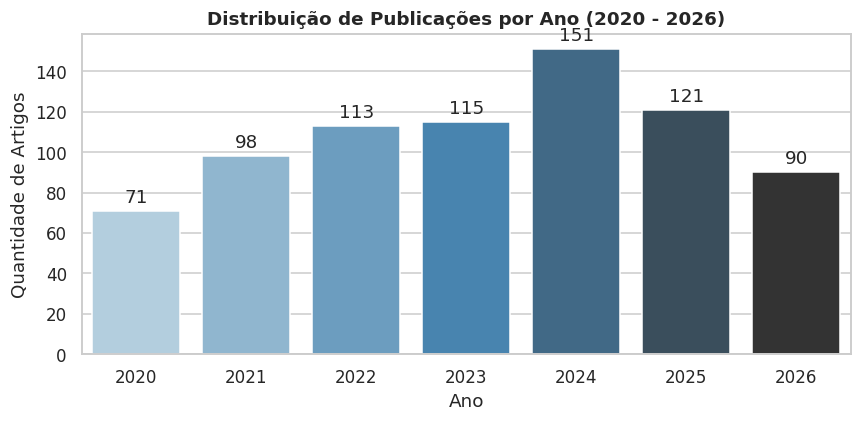

In [3]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

pasta_resultados = '/content/drive/MyDrive/Colab Notebooks/results/first'
os.makedirs(pasta_resultados, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

plt.figure(figsize=(8, 4))
df_ano = df['ano'].dropna().astype(int)
ax1 = sns.countplot(x=df_ano, hue=df_ano, palette='Blues_d', legend=False)
plt.title('Distribuição de Publicações por Ano (2020 - 2026)', fontsize=12, fontweight='bold')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Artigos')

for p in ax1.patches:
    h = int(p.get_height())
    if h > 0:
        ax1.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'artigos_por_ano.png'), dpi=300, bbox_inches='tight')
plt.show()

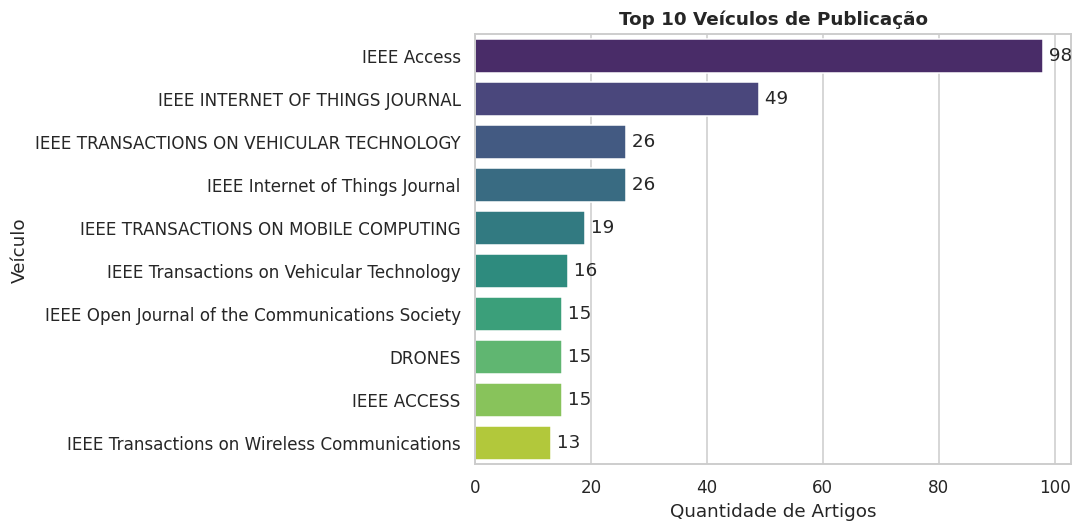

In [4]:
top_veiculos = df[df['veiculo'] != '']['veiculo'].value_counts().head(10)

plt.figure(figsize=(10, 5))
ax3 = sns.barplot(x=top_veiculos.values, y=top_veiculos.index, hue=top_veiculos.index, palette='viridis', legend=False)
plt.title('Top 10 Veículos de Publicação', fontsize=12, fontweight='bold')
plt.xlabel('Quantidade de Artigos')
plt.ylabel('Veículo')

for p in ax3.patches:
    w = int(p.get_width())
    ax3.annotate(f' {w}', (w, p.get_y() + p.get_height() / 2.),
                 ha='left', va='center')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'artigos_por_veiculo.png'), dpi=300, bbox_inches='tight')
plt.show()

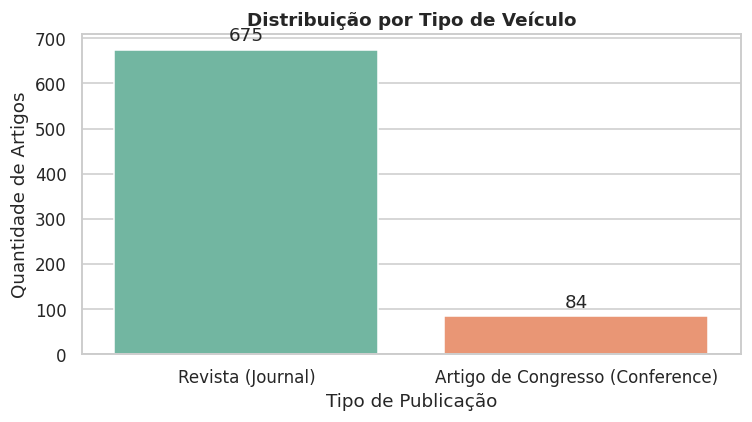

In [5]:
col_tipo = 'tipo_veiculo_rotulo' if 'tipo_veiculo_rotulo' in df.columns else 'tipo_item'
tipos_count = df[col_tipo].value_counts()

plt.figure(figsize=(7, 4))
ax4 = sns.barplot(x=tipos_count.index, y=tipos_count.values, hue=tipos_count.index, palette='Set2', legend=False)
plt.title('Distribuição por Tipo de Veículo', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Publicação')
plt.ylabel('Quantidade de Artigos')

for p in ax4.patches:
    h = int(p.get_height())
    ax4.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'artigos_por_tipo_veiculo.png'), dpi=300, bbox_inches='tight')
plt.show()

--- Top 10 Artigos Mais Citados ---


,titulo,doi,citacoes
0,Multi-Agent Deep Reinforcement Learning-Based ...,10.1109/TCCN.2020.3027695,546
1,Multi-Agent Deep Reinforcement Learning for Ta...,10.1109/TWC.2022.3153316,525
2,Collaborative Multi-Robot Search and Rescue: P...,10.1109/ACCESS.2020.3030190,516
3,Communication and Control in Collaborative UAV...,10.1109/TITS.2023.3248841,385
4,Multi-UAV-Enabled Load-Balance Mobile-Edge Com...,10.1109/JIOT.2020.2971645,371
5,Toward Autonomous Multi-UAV Wireless Network: ...,10.1109/COMST.2023.3323344,331
6,Joint Deployment and Task Scheduling Optimizat...,10.1109/TCYB.2019.2935466,325
7,Multi-Agent DRL for Task Offloading and Resour...,10.1109/TNSM.2021.3096673,274
8,Collaborative Computation Offloading and Resou...,10.1109/JIOT.2021.3063188,257
9,Multi-UAV Cooperative Task Offloading and Reso...,10.1109/TWC.2023.3277801,249


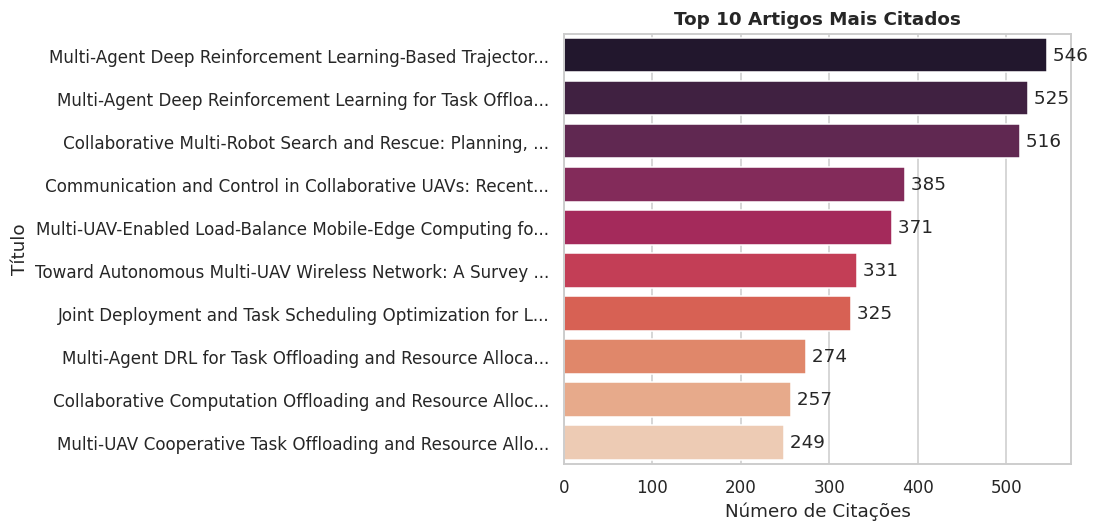

In [6]:
if 'citacoes' in df.columns and df['citacoes'].sum() > 0:
    # Seleção dos 10 artigos mais citados incluindo a coluna DOI
    cols_selecao = ['titulo', 'doi', 'citacoes']
    cols_existentes = [c for c in cols_selecao if c in df.columns]

    top_citados = df.nlargest(10, 'citacoes')[cols_existentes].copy()

    # Exibição da tabela com Título, DOI e Citações
    print("--- Top 10 Artigos Mais Citados ---")
    display(top_citados.reset_index(drop=True))

    # Preparação do título encurtado para a renderização no gráfico
    top_citados['titulo_curto'] = top_citados['titulo'].apply(lambda t: t[:55] + '...' if len(str(t)) > 55 else str(t))

    plt.figure(figsize=(10, 5))
    ax5 = sns.barplot(data=top_citados, x='citacoes', y='titulo_curto', hue='titulo_curto', palette='rocket', legend=False)
    plt.title('Top 10 Artigos Mais Citados', fontsize=12, fontweight='bold')
    plt.xlabel('Número de Citações')
    plt.ylabel('Título')

    for p in ax5.patches:
        w = int(p.get_width())
        ax5.annotate(f' {w}', (w, p.get_y() + p.get_height() / 2.), ha='left', va='center')

    plt.tight_layout()
    plt.savefig(os.path.join(pasta_resultados, 'artigos_mais_citados.png'), dpi=300, bbox_inches='tight')
    plt.show()

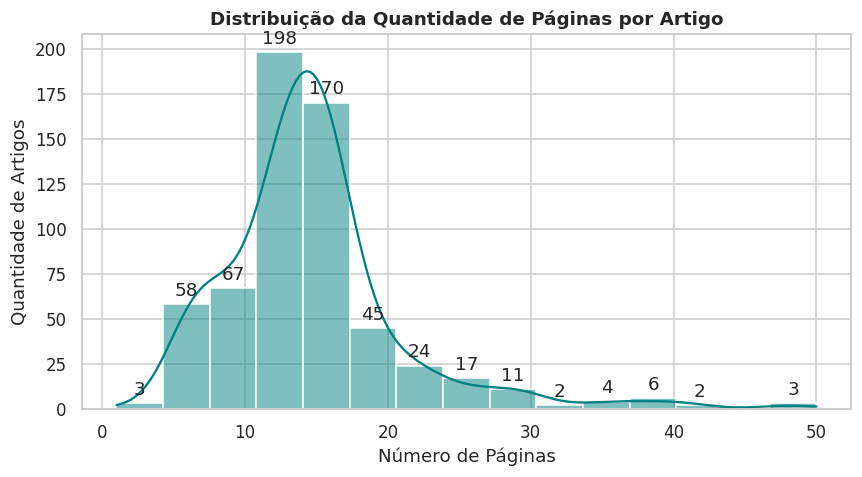

In [7]:
if 'num_paginas' in df.columns and df['num_paginas'].dropna().shape[0] > 0:
    plt.figure(figsize=(8, 4.5))
    df_paginas = df['num_paginas'].dropna()
    ax6 = sns.histplot(df_paginas, bins=15, kde=True, color='teal')
    plt.title('Distribuição da Quantidade de Páginas por Artigo', fontsize=12, fontweight='bold')
    plt.xlabel('Número de Páginas')
    plt.ylabel('Quantidade de Artigos')

    for p in ax6.patches:
        h = int(p.get_height())
        if h > 0:
            ax6.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

    plt.tight_layout()
    plt.savefig(os.path.join(pasta_resultados, 'histograma_paginas.png'), dpi=300, bbox_inches='tight')
    plt.show()

--- Tabela de Distribuição por Faixa de Páginas ---


,Faixa de Páginas,Quantidade de Artigos,Porcentagem (%)
0,0 a 4 págs (Elegível EC3),3,0.40
1,5 a 8 págs,87,11.46
2,9 a 12 págs,114,15.02
3,13 a 16 págs,261,34.39
4,17+ págs,145,19.10
5,Não informado / Sem páginas,149,19.63


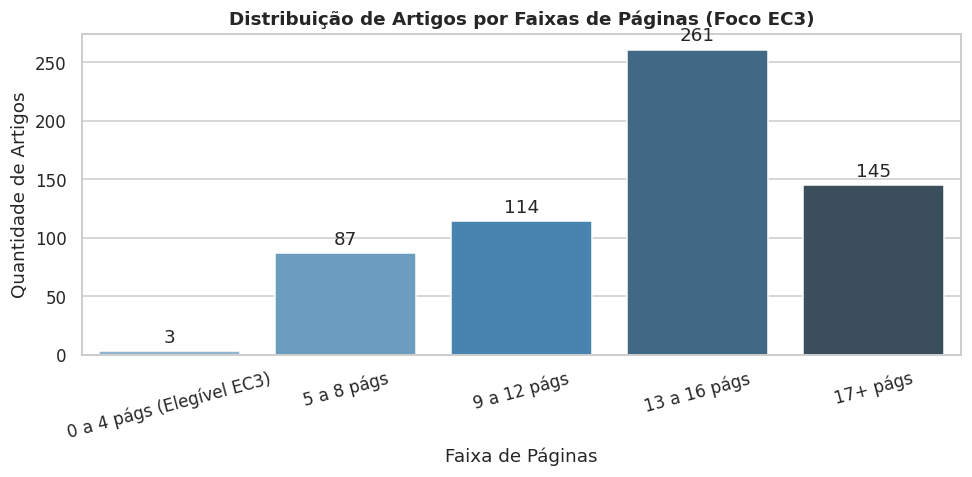

In [8]:
# 1. Agrupamento por faixas
limites = [-1, 4, 8, 12, 16, np.inf]
rotulos = ['0 a 4 págs (Elegível EC3)', '5 a 8 págs', '9 a 12 págs', '13 a 16 págs', '17+ págs']

df['faixa_paginas'] = pd.cut(df['num_paginas'], bins=limites, labels=rotulos)

tabela_paginas = df['faixa_paginas'].value_counts(sort=False).reset_index()
tabela_paginas.columns = ['Faixa de Páginas', 'Quantidade de Artigos']
tabela_paginas['Porcentagem (%)'] = (tabela_paginas['Quantidade de Artigos'] / len(df) * 100).round(2)

sem_info = df['num_paginas'].isna().sum()
if sem_info > 0:
    linha_ausente = pd.DataFrame({
        'Faixa de Páginas': ['Não informado / Sem páginas'],
        'Quantidade de Artigos': [sem_info],
        'Porcentagem (%)': [round(sem_info / len(df) * 100, 2)]
    })
    tabela_paginas = pd.concat([tabela_paginas, linha_ausente], ignore_index=True)

print("--- Tabela de Distribuição por Faixa de Páginas ---")
display(tabela_paginas)

# 2. Plot do Gráfico por Faixa
plt.figure(figsize=(9, 4.5))
df_plot = tabela_paginas[tabela_paginas['Faixa de Páginas'] != 'Não informado / Sem páginas']

ax7 = sns.barplot(
    data=df_plot,
    x='Faixa de Páginas',
    y='Quantidade de Artigos',
    hue='Faixa de Páginas',
    palette='Blues_d',
    legend=False
)

plt.title('Distribuição de Artigos por Faixas de Páginas (Foco EC3)', fontsize=12, fontweight='bold')
plt.xlabel('Faixa de Páginas')
plt.ylabel('Quantidade de Artigos')
plt.xticks(rotation=15)

for p in ax7.patches:
    h = int(p.get_height())
    if h > 0:
        ax7.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'distribuicao_faixa_paginas.png'), dpi=300, bbox_inches='tight')
plt.show()

# Fluxo de Filtragem da SLR (740 -> 50 Artigos)

## 1. Variáveis Utilizadas (`DataBase.csv`)
- **Filtro Rígido:** `num_paginas` (Exclusão se $< 4$).
- **Métricas:** `ano` (2020–2026), `citacoes`.
- **Texto:** `titulo`, `abstract`, `manual_tags`.

## 2. Termos-Chave por Questão de Pesquisa (RQ)
- **RQ1 & RQ4 (Middlewares e Comunicação):** `ros 2`, `dds`, `zenoh`, `qos`, `manet`, `fanet`, `5g`, `6g`.
- **RQ2 & RQ3 (Continuum e Gêmeos Digitais):** `edge computing`, `fog computing`, `cloud`, `continuum`, `digital twin`, `digital shadow`, `digital model`.
- **RQ5 (Decisão e Frota):** `decentralized`, `centralized`, `hierarchical`, `optimization`, `multi-robot`, `swarm`, `heterogeneous`, `uav-ugv`.

## 3. Fórmulas Matemáticas

### Densidade de Citações por Ano
$$\text{Cit}_{\text{ano}} = \frac{\text{citacoes}}{2026 - \text{ano} + 1}$$

### Relevância Semântica (Cosseno sobre TF-IDF)
$$\text{Score}_{\text{TF-IDF}} = \cos(\theta) = \frac{\vec{A} \cdot \vec{B}}{\|\vec{A}\| \|\vec{B}\|}$$

### Pontuação Composta Final (Após Escala Min-Max)
$$\text{Score Final} = (0{,}45 \times \text{Score}_{\text{TF-IDF}}) + (0{,}35 \times \text{Score}_{\text{Ano}}) + (0{,}20 \times \text{Score}_{\text{Cit\_Ano}})$$

## 4. Etapas do Processo
1. Fazer upload do arquivo `DataBase.csv` no Colab.
2. Rodar o script Python para aplicar os filtros e calcular as pontuações.
3. Descarregar o arquivo gerado `artigos_filtrados_50.csv`.
4. Importar/filtrar as chaves `id_zotero` na coleção do Zotero para a leitura final de Título e Resumo.

In [1]:
import os
import pandas as pd
import numpy as np
from google.colab import drive
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

# --- FUNÇÕES DE PROCESSAMENTO ---

def aplicar_filtro_paginas(dataframe, min_paginas=4):
    return dataframe[(dataframe['num_paginas'].isna()) | (dataframe['num_paginas'] >= min_paginas)].copy()

def calcular_densidade_citacoes(dataframe, ano_referencia=2026):
    anos = ano_referencia - dataframe['ano'] + 1
    return dataframe['citacoes'] / anos

def calcular_relevancia_tfidf(dataframe, texto_escopo):
    textos = (
        dataframe['titulo'].fillna('') + ' ' +
        dataframe['abstract'].fillna('') + ' ' +
        dataframe['manual_tags'].fillna('')
    )
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
    matriz = vectorizer.fit_transform([texto_escopo] + textos.tolist())
    return cosine_similarity(matriz[0:1], matriz[1:]).flatten()

def normalizar_e_pontuar(dataframe, w_rel=0.45, w_rec=0.35, w_cit=0.20):
    scaler = MinMaxScaler()
    norm = scaler.fit_transform(dataframe[['score_tfidf', 'ano', 'citacoes_por_ano']])

    dataframe['norm_relevancia'] = norm[:, 0]
    dataframe['norm_recencia']   = norm[:, 1]
    dataframe['norm_cit_ano']    = norm[:, 2]

    dataframe['score_final'] = (
        w_rel * dataframe['norm_relevancia'] +
        w_rec * dataframe['norm_recencia'] +
        w_cit * dataframe['norm_cit_ano']
    )
    return dataframe

# --- EXECUÇÃO DO PIPELINE ---

drive.mount('/content/drive')

caminho_entrada = '/content/drive/MyDrive/Colab Notebooks/PRE-TRIAGEM/DataBase.csv'
pasta_resultados = '/content/drive/MyDrive/Colab Notebooks/results'
os.makedirs(pasta_resultados, exist_ok=True)

escopo = """
Coordination of heterogeneous multi-robot systems and swarms in the cyber-physical computing continuum.
Middlewares and communication protocols: ROS 2, DDS, Zenoh, latency, throughput, and QoS requirements.
Processing and task offloading distribution across onboard robot, local edge, fog computing, and cloud infrastructure.
Digital coupling and integration: Digital Model, Digital Shadow, and Digital Twin frameworks.
Communication modes and topologies: explicit and implicit data exchange, ad-hoc MANET, FANET, cellular 5G, 6G, and URLLC networks.
Decision-making architectures and methods: centralized, decentralized, and hierarchical structures using optimization, rules, heuristics, deep reinforcement learning, and negotiation protocols.
Coordination scope: multi-UAV, multi-UGV, mixed fleets, task allocation, trajectory planning, movement control, and shared resource management.
"""

# Fluxo principal chamando as funções
df = pd.read_csv(caminho_entrada)
df_filtrado = aplicar_filtro_paginas(df)
df_filtrado['citacoes_por_ano'] = calcular_densidade_citacoes(df_filtrado)
df_filtrado['score_tfidf'] = calcular_relevancia_tfidf(df_filtrado, escopo)
df_final = normalizar_e_pontuar(df_filtrado)

# Seleção do Top 50 e exportação
top_50 = df_final.sort_values(by='score_final', ascending=False).head(50).copy()
top_50.to_csv(os.path.join(pasta_resultados, 'artigos_top50_filtrados.csv'), index=False)

# --- EXIBIÇÃO DA TABELA DE SCORES FORMATADA ---

# Seleção de colunas para exibição limpa
colunas_exibicao = [
    'titulo', 'ano', 'citacoes',
    'norm_relevancia', 'norm_recencia', 'norm_cit_ano', 'score_final'
]

tabela_scores = top_50[colunas_exibicao].reset_index(drop=True)
tabela_scores.index = tabela_scores.index + 1  # Ajusta o índice para começar em Rank 1
tabela_scores.index.name = 'Rank'

# Arredondamento dos scores para 4 casas decimais
cols_decimais = ['norm_relevancia', 'norm_recencia', 'norm_cit_ano', 'score_final']
tabela_scores[cols_decimais] = tabela_scores[cols_decimais].round(4)

print("--- TOP 50 ARTIGOS SELECIONADOS E SEUS SCORES ---")
display(tabela_scores)

print("\nProcessamento modular e exibição concluídos com sucesso!")

Mounted at /content/drive
--- TOP 50 ARTIGOS SELECIONADOS E SEUS SCORES ---


,titulo,ano,citacoes,norm_relevancia,norm_recencia,norm_cit_ano,score_final
Rank,,,,,,,
1,Guarded Swarms: Building Trusted Autonomy Thro...,2026,2,0.8386,1.0000,0.0190,0.7312
2,Multi-Agent Deep Reinforcement Learning for Ta...,2022,525,0.8663,0.3333,1.0000,0.7065
3,MADTwin: a framework for multi-agent digital t...,2024,30,1.0000,0.6667,0.0952,0.7024
4,"Joint Task Offloading, Resource Allocation, an...",2024,249,0.6649,0.6667,0.7905,0.6907
5,QoS-Oriented Task Offloading in NOMA-Based Mul...,2026,55,0.4915,1.0000,0.5238,0.6760
6,Cyber-physical system architecture of autonomo...,2024,30,0.9211,0.6667,0.0952,0.6669
7,"Exploring the synergy of human-robot teaming, ...",2026,62,0.4393,1.0000,0.5905,0.6658
8,Multi-UAV Cooperative Task Offloading and Reso...,2024,249,0.6005,0.6667,0.7905,0.6617
9,Enhancing UAV-assisted vehicle edge computing ...,2025,25,0.7643,0.8333,0.1190,0.6594



Processamento modular e exibição concluídos com sucesso!


Procurando as informações dos 50 artigos filtrados

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_4408/3711550178.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=counts_ano.index, y=counts_ano.values, palette='Blues_d')


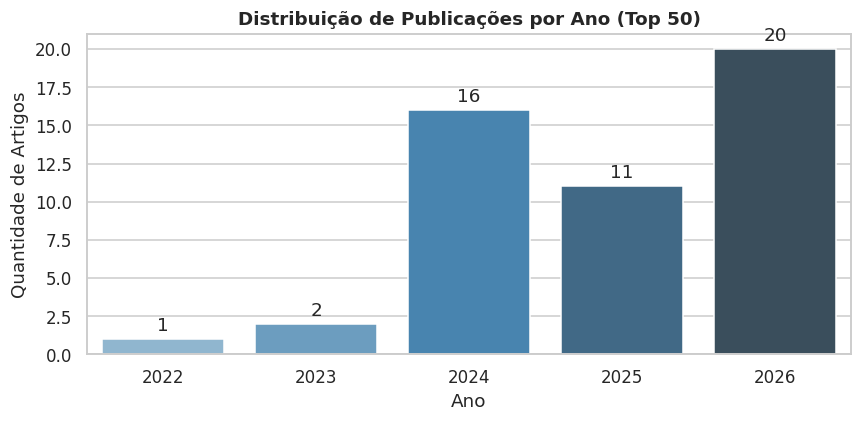

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Montar o Drive (se necessário)
drive.mount('/content/drive')

# Caminho do arquivo dos 50 filtrados e pasta de resultados
caminho_top50 = '/content/drive/MyDrive/Colab Notebooks/results/artigos_top50_filtrados.csv'
pasta_resultados = '/content/drive/MyDrive/Colab Notebooks/results/top50'
os.makedirs(pasta_resultados, exist_ok=True)

# Carregar o DataFrame dos Top 50
df = pd.read_csv(caminho_top50)

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

# 1. Gráfico de Distribuição por Ano (Top 50)
plt.figure(figsize=(8, 4))
df_ano = df['ano'].dropna().astype(int)
counts_ano = df_ano.value_counts().sort_index()

ax1 = sns.barplot(x=counts_ano.index, y=counts_ano.values, palette='Blues_d')
plt.title('Distribuição de Publicações por Ano (Top 50)', fontsize=12, fontweight='bold')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Artigos')

for p in ax1.patches:
    h = int(p.get_height())
    if h > 0:
        ax1.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'top50_artigos_por_ano.png'), dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_4408/3935246216.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(x=top_veiculos.values, y=top_veiculos.index, palette='viridis')


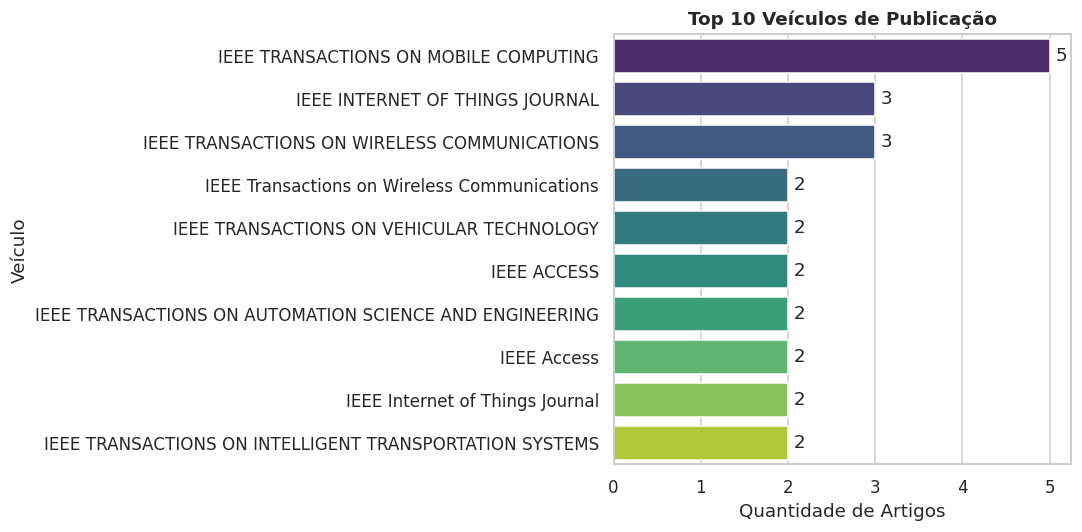

/tmp/ipykernel_4408/3935246216.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax4 = sns.barplot(x=tipos_count.index, y=tipos_count.values, palette='Set2')


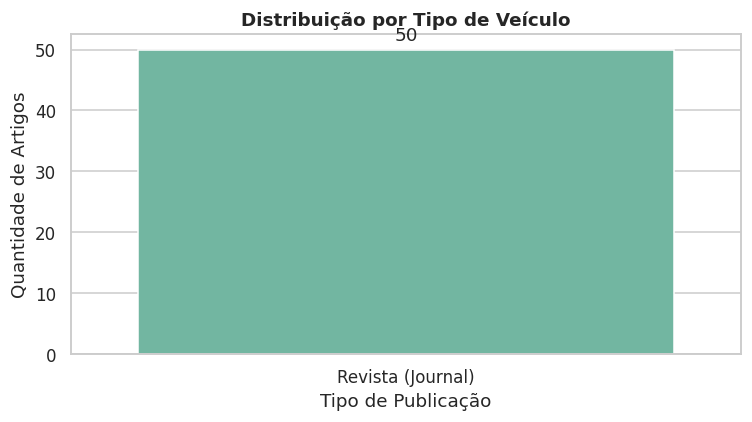

In [10]:
# 2. Top 10 Veículos de Publicação
top_veiculos = df[df['veiculo'].notna() & (df['veiculo'] != '')]['veiculo'].value_counts().head(10)

plt.figure(figsize=(10, 5))
ax3 = sns.barplot(x=top_veiculos.values, y=top_veiculos.index, palette='viridis')
plt.title('Top 10 Veículos de Publicação', fontsize=12, fontweight='bold')
plt.xlabel('Quantidade de Artigos')
plt.ylabel('Veículo')

for p in ax3.patches:
    w = int(p.get_width())
    ax3.annotate(f' {w}', (w, p.get_y() + p.get_height() / 2.), ha='left', va='center')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'artigos_por_veiculo.png'), dpi=300, bbox_inches='tight')
plt.show()

# 3. Distribuição por Tipo de Veículo (Journal vs Conference)
col_tipo = 'tipo_veiculo_rotulo' if 'tipo_veiculo_rotulo' in df.columns else 'tipo_item'
tipos_count = df[col_tipo].value_counts()

plt.figure(figsize=(7, 4))
ax4 = sns.barplot(x=tipos_count.index, y=tipos_count.values, palette='Set2')
plt.title('Distribuição por Tipo de Veículo', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Publicação')
plt.ylabel('Quantidade de Artigos')

for p in ax4.patches:
    h = int(p.get_height())
    ax4.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'artigos_por_tipo_veiculo.png'), dpi=300, bbox_inches='tight')
plt.show()

--- Top 10 Artigos Mais Citados ---


,titulo,doi,citacoes
0,Multi-Agent Deep Reinforcement Learning for Ta...,10.1109/TWC.2022.3153316,525
1,"Joint Task Offloading, Resource Allocation, an...",10.1109/TMC.2024.3350078,249
2,Multi-UAV Cooperative Task Offloading and Reso...,10.1109/TWC.2023.3277801,249
3,Swarm-SLAM: Sparse Decentralized Collaborative...,10.1109/LRA.2023.3333742,176
4,Deep Reinforcement Learning Based Resource All...,10.1109/TCOMM.2022.3226193,173
5,Multi-Objective Optimization for Multi-UAV-Ass...,10.1109/TMC.2024.3446819,135
6,DRL-Based Resource Allocation and Trajectory P...,10.1109/TVT.2024.3357086,104
7,Task Offloading and Trajectory Optimization fo...,10.1109/TMC.2024.3442909,93
8,Resilient Consensus Control of Heterogeneous M...,10.1109/TASE.2024.3420697,79
9,"Exploring the synergy of human-robot teaming, ...",10.1007/s10845-025-02580-x,62


/tmp/ipykernel_4408/468669708.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax5 = sns.barplot(data=top_citados, x='citacoes', y='titulo_curto', palette='rocket')


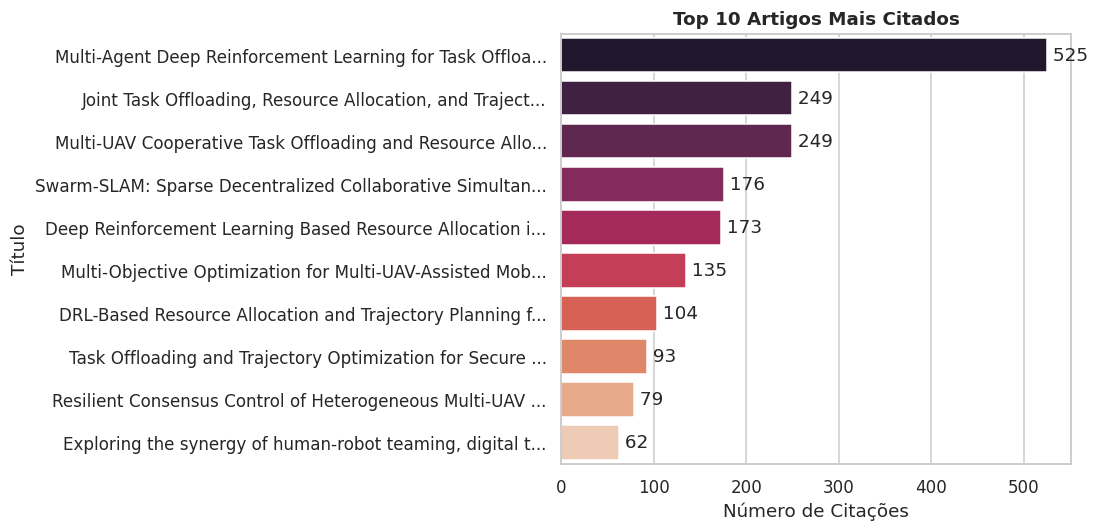

In [11]:
# 4. Top 10 Artigos Mais Citados
if 'citacoes' in df.columns and df['citacoes'].sum() > 0:
    cols_selecao = ['titulo', 'doi', 'citacoes']
    cols_existentes = [c for c in cols_selecao if c in df.columns]

    top_citados = df.nlargest(10, 'citacoes')[cols_existentes].copy()

    print("--- Top 10 Artigos Mais Citados ---")
    display(top_citados.reset_index(drop=True))

    top_citados['titulo_curto'] = top_citados['titulo'].apply(lambda t: t[:55] + '...' if len(str(t)) > 55 else str(t))

    plt.figure(figsize=(10, 5))
    ax5 = sns.barplot(data=top_citados, x='citacoes', y='titulo_curto', palette='rocket')
    plt.title('Top 10 Artigos Mais Citados', fontsize=12, fontweight='bold')
    plt.xlabel('Número de Citações')
    plt.ylabel('Título')

    for p in ax5.patches:
        w = int(p.get_width())
        ax5.annotate(f' {w}', (w, p.get_y() + p.get_height() / 2.), ha='left', va='center')

    plt.tight_layout()
    plt.savefig(os.path.join(pasta_resultados, 'artigos_mais_citados.png'), dpi=300, bbox_inches='tight')
    plt.show()

--- Tabela de Distribuição por Faixa de Páginas ---


,Faixa de Páginas,Quantidade de Artigos,Porcentagem (%)
0,0 a 4 págs (Elegível EC3),0,0.0
1,5 a 8 págs,1,2.0
2,9 a 12 págs,4,8.0
3,13 a 16 págs,19,38.0
4,17+ págs,15,30.0
5,Não informado / Sem páginas,11,22.0


/tmp/ipykernel_4408/2898044398.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax7 = sns.barplot(


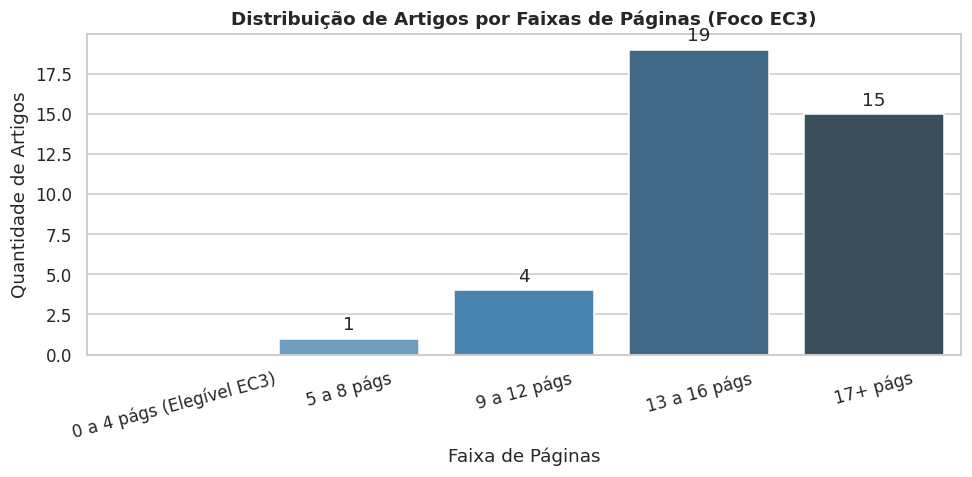

In [12]:
# 5. Agrupamento por Faixas de Páginas
limites = [-1, 4, 8, 12, 16, np.inf]
rotulos = ['0 a 4 págs (Elegível EC3)', '5 a 8 págs', '9 a 12 págs', '13 a 16 págs', '17+ págs']

df['faixa_paginas'] = pd.cut(df['num_paginas'], bins=limites, labels=rotulos)

tabela_paginas = df['faixa_paginas'].value_counts(sort=False).reset_index()
tabela_paginas.columns = ['Faixa de Páginas', 'Quantidade de Artigos']
tabela_paginas['Porcentagem (%)'] = (tabela_paginas['Quantidade de Artigos'] / len(df) * 100).round(2)

sem_info = df['num_paginas'].isna().sum()
if sem_info > 0:
    linha_ausente = pd.DataFrame({
        'Faixa de Páginas': ['Não informado / Sem páginas'],
        'Quantidade de Artigos': [sem_info],
        'Porcentagem (%)': [round(sem_info / len(df) * 100, 2)]
    })
    tabela_paginas = pd.concat([tabela_paginas, linha_ausente], ignore_index=True)

print("--- Tabela de Distribuição por Faixa de Páginas ---")
display(tabela_paginas)

# Gráfico por Faixa de Páginas
plt.figure(figsize=(9, 4.5))
df_plot = tabela_paginas[tabela_paginas['Faixa de Páginas'] != 'Não informado / Sem páginas']

ax7 = sns.barplot(
    data=df_plot,
    x='Faixa de Páginas',
    y='Quantidade de Artigos',
    palette='Blues_d'
)

plt.title('Distribuição de Artigos por Faixas de Páginas (Foco EC3)', fontsize=12, fontweight='bold')
plt.xlabel('Faixa de Páginas')
plt.ylabel('Quantidade de Artigos')
plt.xticks(rotation=15)

for p in ax7.patches:
    h = int(p.get_height())
    if h > 0:
        ax7.annotate(f'{h}', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(pasta_resultados, 'distribuicao_faixa_paginas.png'), dpi=300, bbox_inches='tight')
plt.show()